# Outlier detection

**Author:** Mio Diaz

**Purpose:** Mid-Report 2 

**Section 3: Outlier Detection**.

The assignment asks for all of the following:

| # | Assignment item | Where in this notebook |
|---|---|---|
| a | Apply at least two outlier detection methods | §3 statistical baseline, §4 DBSCAN, §5 One-Class SVM, §6 GMM |
| b | Clearly define what an "outlier" is in our project context | §2 |
| c | Visualize detected outliers and explain their characteristics | §7, §8 |
| d | Discuss potential causes (data errors, rare but valid cases, automation, ...) | §9 |
| e | Evaluate the impact of outliers on clustering and dimensionality reduction | §10 |
| — | Feed Section 4 (integration, insights, limitations) | §12 |

**Methods come from the course only:** Lesson 11 (statistical approach, DBSCAN noise points) and Lesson 12 (One-Class SVM, Gaussian Mixture Model). The VAE from Lesson 12.4 is left out (it needs PyTorch and is heavy for ~15 tabular features); this goes in limitations.

**Data:** Table A (`data/merged_dataset.csv`, 62,627 repos × 49 columns).

- **Population:** outliers are detected among **real projects**, repos active in **≥ 3 separate months of 2024** (7,890 repos, 12.6%). The other 87% are one-burst repos (mostly active in 1–2 months) that were never maintained, so "decay" does not apply to them; they are described in §2 and reported as their own group.
- **Normal** = the dense middle of the real-project population (consistently maintained). **Outliers** sit on either tail: the *low* tail (projects that went quiet → likely decaying) and the *high* tail (abnormal volume → automation, bots, mirrors).
- **Robustness check:** the analysis is rerun on the stricter population active ≥ 6 months (§11).
- **Features:** 2024 GH Archive activity only. deps.dev / Scorecard value columns are 98–100% missing (structural) and only used in the packaged subset (§11). Coverage flags (`has_package`, ...) are kept out of the feature matrix and used for interpretation.
- **Label:** `inactive_next_365d` is **not** a feature. It is used afterwards to *validate* the definition: low-tail outliers should go inactive more often than the population's 47% base rate.


## 0. Dependencies on teammates

Section 3 can start on its own; only §10 (impact on clustering / DR) depends on the other sections. To keep the three sections consistent:

- **Shared population and feature matrix** (defined in §1–2, to send to the clustering and DR owners):
  - population: repos with `active_months_2024 >= 3` (7,890 repos);
  - features: GH Archive 2024 activity counts and H1 / H2 qualifying events (log1p) + `days_since_last_push_at_cutoff` (NaN → 366), then `StandardScaler`;
  - coverage flags and `inactive_next_365d` are **not** features.
- **Open questions for teammates:**
  - [ ] Clustering: which algorithms, which `k` / `eps` / `minPts`, same features and scaling?
  - [ ] DR: PCA components kept, t-SNE / UMAP params, same features and scaling?
  - [ ] Are they clustering the same ≥ 3-month population or all 62,627 repos? (If all repos, §10 should say so.)
  - [ ] Do they want the outlier flags (column `is_outlier`) exported so they can rerun with outliers removed?
  - [ ] If the clustering owner also uses DBSCAN, agree on `eps` / `minPts` so §4 and their section don't contradict each other (their noise points = our DBSCAN outliers).
- Until answers come back, §10 uses a **baseline K-means + PCA** with the settings in the `K` / `FEATURES` block, which can be swapped for theirs.

**Notes:**

- **Assignment item:** (coordination) dependencies and shared settings
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 1. Setup and feature matrix

- Load `merged_dataset.csv`.
- **Population:** keep repos with `active_months_2024 >= 3` (`P`, 7,890 repos); the reasoning is in §2.
- **Features** (2024 GH Archive only), `log1p` on all counts:
  - volume: push, issue, issue-comment, PR, review, release events; stars received; forks;
  - breadth: distinct actors, active days, active months;
  - **trend** (needed to see the low / decaying tail): `qualifying_events_h1_2024`, `qualifying_events_h2_2024` as separate columns instead of the H2/H1 ratio (the ratio is undefined for the 29% of projects that started in H2);
  - recency: `days_since_last_push_at_cutoff`, NaN (79 projects with no push) filled with 366 = "no push in window".
- Then `StandardScaler`.
- **Not features:** identifiers, deps.dev / Scorecard value columns (98–100% missing), coverage flags (`has_package` etc. would get z ≈ 8 for a rare 1 and dominate distances), and `inactive_next_365d` (kept aside for validation).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("../data")
FIG_DIR = Path("../figures")
REPORT_IMG = Path("../report/img")

def save_fig(fig, name):
    """Write a figure to figures/ as SVG and report/img/ as PNG (no timestamp, so re-runs give clean diffs)."""
    fig.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight", metadata={"Date": None})
    fig.savefig(REPORT_IMG / f"{name}.png", bbox_inches="tight", dpi=150)

A = pd.read_csv(DATA / "merged_dataset.csv")
print(f"Table A: {len(A):,} rows x {A.shape[1]} cols")

Table A: 62,627 rows x 49 cols


In [2]:
# TODO: P = A[A["active_months_2024"] >= 3]
# TODO: FEATURES list, X = StandardScaler(log1p(P[FEATURES])) with days_since_last_push NaN -> 366
# TODO: y = P["inactive_next_365d"] (validation only)
# Sanity checks: no NaN in X, label and coverage flags not in X, len(X) == 7,890

**Notes:**

- **Assignment item:** Outlier Detection → data used; population filter; why sparse deps.dev / Scorecard columns and coverage flags are excluded
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 2. What counts as normal, and what counts as an outlier

- **2a–2d:** describe the full population. It is dominated by tiny one-burst repos (median 1 actor, 1 active month, 3 pushes), so it cannot be the reference for "maintained".
- **2e:** where to draw the line for a "real project" (active months vs share of repos and 2025 inactivity).
- **2f:** describe the real-project population (≥ 3 active months): its dense middle is *normal* = consistently maintained.
- **2g:** the definition. Outliers are on **both tails** of the real-project population:
  - **low tail → decaying:** projects that were active and then went quiet (few H2 events, long time since last push);
  - **high tail → abnormal volume:** automation / bots / mirrors (huge push counts, active nearly every day, one actor), plus rare-but-valid very large community projects;
  - **data artifacts** can show up on either side (duplicate names, collection gaps).
- Type of outlier (Lesson 11.2): mostly **global** within the population; packaged repos give a **contextual** view (§11); groups of near-identical bot repos may be **collective** outliers.
- Expected outlier share ~1% per tail-agnostic method (One-Class SVM `nu`, GMM likelihood cutoff), justified in 2g.

### 2a. Descriptive statistics of 2024 activity

First the **full population** (Table A, all 62,627 repos), to show why it can't be the reference for "maintained". One row per activity feature:
mean vs median, upper percentiles, max, share of zeros and skewness.

In [3]:
ACTIVITY = [
    "push_events_2024", "issue_events_2024", "issue_comment_events_2024",
    "pull_request_events_2024", "review_events_2024", "release_events_2024",
    "stars_received_2024", "fork_events_2024", "distinct_actors_2024",
    "active_months_2024", "active_days_2024", "days_since_last_push_at_cutoff",
]
d = A[ACTIVITY]
desc = pd.DataFrame({
    "mean": d.mean(),
    "median": d.median(),
    "p75": d.quantile(0.75),
    "p90": d.quantile(0.90),
    "p99": d.quantile(0.99),
    "max": d.max(),
    "% zero": (d == 0).mean() * 100,
    "skew": d.skew(),
}).round(2)
desc

,mean,median,p75,p90,p99,max,% zero,skew
push_events_2024,43.77,3.0,14.0,35.0,301.00,362071.0,1.91,136.80
issue_events_2024,1.61,0.0,0.0,0.0,13.00,51240.0,95.41,248.46
issue_comment_events_2024,2.41,0.0,0.0,0.0,27.00,30312.0,93.83,216.38
pull_request_events_2024,3.60,0.0,0.0,2.0,67.00,6209.0,84.62,69.51
review_events_2024,2.08,0.0,0.0,0.0,15.74,9237.0,97.23,79.89
release_events_2024,0.25,0.0,0.0,0.0,4.00,361.0,97.09,45.88
stars_received_2024,1.84,0.0,0.0,0.0,12.00,8745.0,90.41,96.29
fork_events_2024,0.40,0.0,0.0,0.0,4.00,1653.0,94.88,90.32
distinct_actors_2024,1.54,1.0,1.0,2.0,7.00,1251.0,0.00,86.88
active_months_2024,1.70,1.0,1.0,3.0,12.00,12.0,0.00,3.79


### 2b. The typical repo profile

Share of repos that match each "tiny repo" condition. Most repos match most conditions, so if we used the full population, a *tiny one-burst repo* would be "normal" and every maintained project would look like an outlier. That is the wrong way round for this project, so §2e–2f narrow the population.

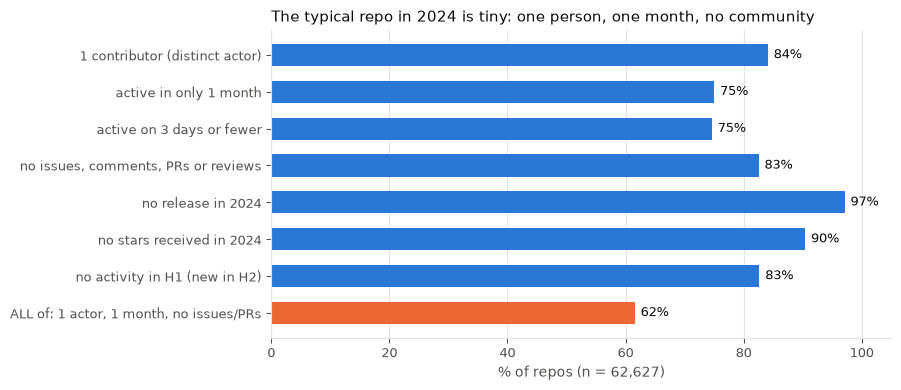

In [4]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"

def style(ax):
    """Recessive axes: no top/right spines, light grid, muted tick labels."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

engagement = ["issue_events_2024", "issue_comment_events_2024", "pull_request_events_2024", "review_events_2024"]
profile = pd.Series({
    "1 contributor (distinct actor)": A["distinct_actors_2024"].eq(1).mean(),
    "active in only 1 month": A["active_months_2024"].eq(1).mean(),
    "active on 3 days or fewer": A["active_days_2024"].le(3).mean(),
    "no issues, comments, PRs or reviews": A[engagement].sum(axis=1).eq(0).mean(),
    "no release in 2024": A["release_events_2024"].eq(0).mean(),
    "no stars received in 2024": A["stars_received_2024"].eq(0).mean(),
    "no activity in H1 (new in H2)": A["h1_qualifying_events_zero"].eq(1).mean(),
    "ALL of: 1 actor, 1 month, no issues/PRs": (
        A["distinct_actors_2024"].eq(1) & A["active_months_2024"].eq(1) & A[engagement].sum(axis=1).eq(0)
    ).mean(),
}).mul(100)

fig, ax = plt.subplots(figsize=(8, 4))
colors = [BLUE] * (len(profile) - 1) + [ORANGE]
ax.barh(profile.index[::-1], profile.values[::-1], color=colors[::-1], height=0.6)
for y, v in enumerate(profile.values[::-1]):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 105)
ax.set_xlabel("% of repos (n = 62,627)", color=MUTED)
ax.set_title("The typical repo in 2024 is tiny: one person, one month, no community", loc="left", fontsize=11, color=INK)
style(ax)
save_fig(fig, "outliers_normal_profile")
plt.show()

### 2c. Distributions: raw vs log scale

Raw counts are so skewed that a histogram is a single bar at zero; on a `log1p` scale the shape becomes visible.
This is the reason every outlier method below works on log-transformed features — otherwise "outlier" just means "biggest".

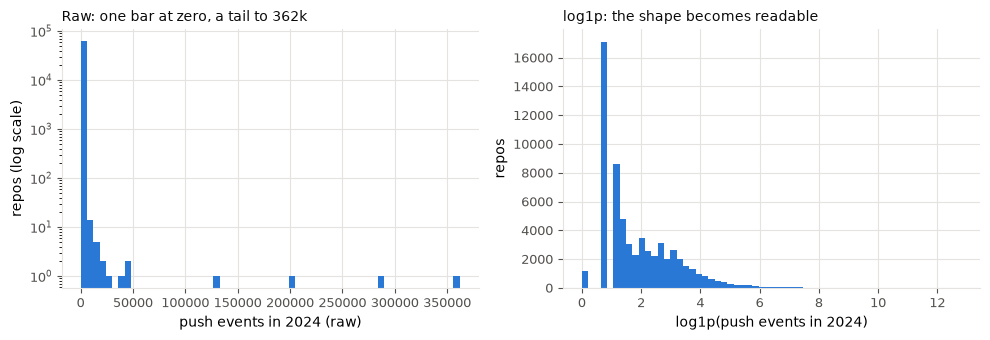

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
x = A["push_events_2024"]
axes[0].hist(x, bins=60, color=BLUE)
axes[0].set(yscale="log", xlabel="push events in 2024 (raw)", ylabel="repos (log scale)")
axes[0].set_title("Raw: one bar at zero, a tail to 362k", loc="left", fontsize=10, color=INK)
axes[1].hist(np.log1p(x), bins=60, color=BLUE)
axes[1].set(xlabel="log1p(push events in 2024)", ylabel="repos")
axes[1].set_title("log1p: the shape becomes readable", loc="left", fontsize=10, color=INK)
for ax in axes:
    style(ax)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
fig.tight_layout()
save_fig(fig, "outliers_push_raw_vs_log")
plt.show()

### 2d. Where the tail starts

Small multiples of key features on a `log1p` scale. Solid line = median (the normal repo), dashed line = 99th percentile (where the extreme tail starts).

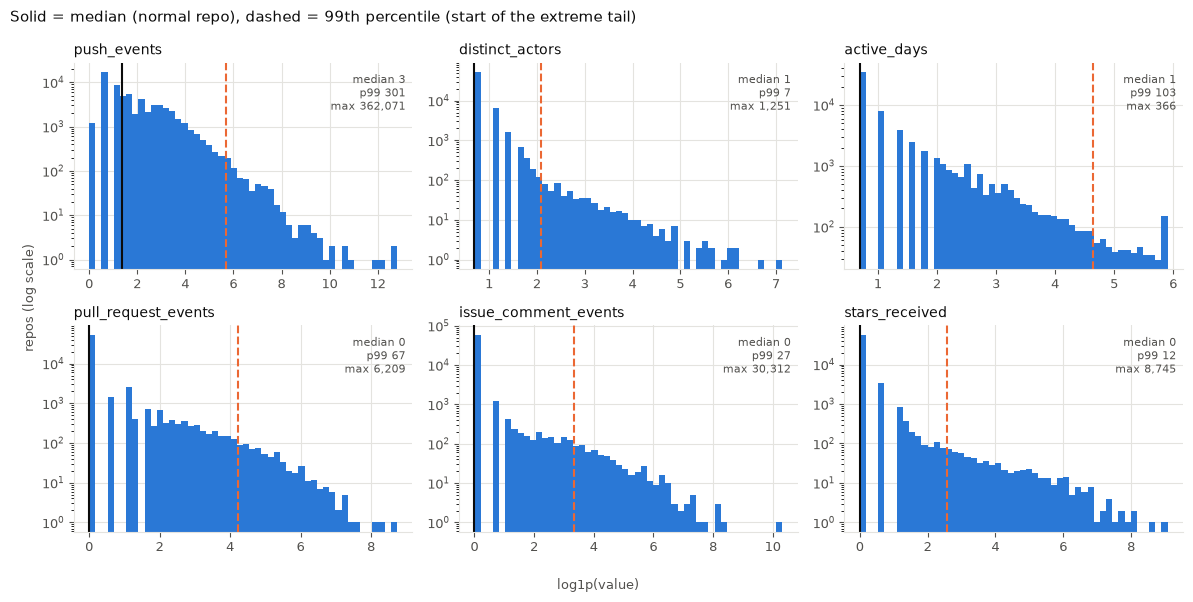

In [6]:
KEY = ["push_events_2024", "distinct_actors_2024", "active_days_2024",
       "pull_request_events_2024", "issue_comment_events_2024", "stars_received_2024"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, KEY):
    v = np.log1p(A[col])
    ax.hist(v, bins=50, color=BLUE)
    med, p99 = A[col].median(), A[col].quantile(0.99)
    ax.axvline(np.log1p(med), color=INK, linewidth=1.5)
    ax.axvline(np.log1p(p99), color=ORANGE, linewidth=1.5, linestyle="--")
    ax.set_yscale("log")
    ax.set_title(col.replace("_2024", ""), loc="left", fontsize=10, color=INK)
    ax.text(0.98, 0.95, f"median {med:g}\np99 {p99:g}\nmax {A[col].max():,.0f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=8, color=MUTED)
    style(ax)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
fig.supxlabel("log1p(value)", color=MUTED, fontsize=9)
fig.supylabel("repos (log scale)", color=MUTED, fontsize=9)
fig.suptitle("Solid = median (normal repo), dashed = 99th percentile (start of the extreme tail)",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
save_fig(fig, "outliers_key_distributions")
plt.show()

### 2e. Where to draw the line for a "real project"

Number of repos and their 2025 inactivity rate by number of active months in 2024. The line is set on domain grounds ("someone came back to it in at least 3 separate months"); the label is only shown to describe the groups, not to tune the cutoff.

In [ ]:
by_month = A.groupby("active_months_2024")["inactive_next_365d"].agg(repos="size", inactive_rate="mean")
months = by_month.index.to_numpy()
in_pop = months >= 3

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(months, by_month["repos"], color=np.where(in_pop, BLUE, GRID), width=0.7)
axes[0].set(yscale="log", xlabel="active months in 2024", ylabel="repos (log scale)")
axes[0].set_title("Most repos are active in only 1–2 months", loc="left", fontsize=10, color=INK)
axes[1].bar(months, by_month["inactive_rate"] * 100, color=np.where(in_pop, BLUE, GRID), width=0.7)
axes[1].set(xlabel="active months in 2024", ylabel="% inactive in 2025", ylim=(0, 100))
axes[1].set_title("Inactivity falls steadily with active months", loc="left", fontsize=10, color=INK)
for ax in axes:
    style(ax)
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_xticks(months)
    ax.axvline(2.5, color=ORANGE, linestyle="--", linewidth=1.5)
axes[0].text(2.6, by_month["repos"].max(), " real projects (≥ 3 months) →", color=ORANGE, fontsize=9, va="top")
fig.tight_layout()
save_fig(fig, "outliers_population_cutoff")
plt.show()
by_month.assign(inactive_rate=lambda t: t["inactive_rate"].round(2)).T

### 2f. The real-project population

Population split, then the same descriptive statistics within real projects. Here the middle of the distribution is a consistently maintained repo, and both tails are visible.

In [ ]:
P = A[A["active_months_2024"] >= 3].copy()
groups = pd.Series(np.select(
    [A["active_months_2024"] >= 6, A["active_months_2024"] >= 3],
    ["real project, ≥ 6 months (robustness set)", "real project, 3–5 months"],
    default="one-burst repo, 1–2 months (excluded)"), index=A.index)
split = A.groupby(groups)["inactive_next_365d"].agg(repos="size", inactive_rate="mean")
split["% of repos"] = split["repos"] / len(A) * 100
display(split.round(2))
print(f"Real-project population P: {len(P):,} repos ({len(P) / len(A):.1%}), inactive rate {P['inactive_next_365d'].mean():.2f}")

TREND = ["qualifying_events_h1_2024", "qualifying_events_h2_2024"]
dP = P[ACTIVITY + TREND]
pd.DataFrame({
    "p1": dP.quantile(0.01),
    "p25": dP.quantile(0.25),
    "median": dP.median(),
    "p75": dP.quantile(0.75),
    "p99": dP.quantile(0.99),
    "max": dP.max(),
    "% zero": (dP == 0).mean() * 100,
}).round(1)

In [ ]:
# Both tails inside the real-project population: the low tail (went quiet) and the high tail (huge volume).
TAILS = [
    ("days_since_last_push_at_cutoff", "days since last push (higher = quieter)", False),
    ("qualifying_events_h2_2024", "log1p(qualifying events in H2 2024)", True),
    ("push_events_2024", "log1p(push events in 2024)", True),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (col, label, use_log) in zip(axes, TAILS):
    v = P[col].fillna(366)
    v = np.log1p(v) if use_log else v
    ax.hist(v, bins=40, color=BLUE)
    for q, ls in [(0.01, ":"), (0.5, "-"), (0.99, "--")]:
        ax.axvline(v.quantile(q), color=INK if q == 0.5 else ORANGE, linestyle=ls, linewidth=1.5)
    ax.set(xlabel=label, ylabel="repos")
    style(ax)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
fig.suptitle("Real projects (≥ 3 active months): solid = median, dotted = p1, dashed = p99",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
save_fig(fig, "outliers_project_tails")
plt.show()

### 2g. Definition

> **Within real projects (≥ 3 active months in 2024), an outlier is a repo whose 2024 activity profile is far from the consistently-maintained middle, on the log scale, in either direction.**
>
> - **Low-side outliers (decaying):** the project was active and then went quiet — few or no events in H2, a long time since the last push.
> - **High-side outliers (abnormal volume):** activity far beyond what maintenance needs — automation, bots, mirrors, daily auto-updates — or, rarely, a very large community project.

- **Expected share:** ~1% (One-Class SVM `nu = 0.01`, GMM bottom 1% likelihood). TODO: justify from §3 baseline counts.
- **Side:** each outlier is tagged *low* or *high* afterwards (e.g. by the sign of its mean z-score on the volume features), so the two tails can be analysed separately.
- **Validation (not used for detection):** low-side outliers should have a 2025 inactivity rate well above the population's 47%; high-side outliers should not.

**Notes:**

- **Assignment item:** Outlier Detection → clearly define what constitutes an outlier in your project context
- **What it shows:**
  - **Full population (2a–2d):** the median repo in 2024 has 3 pushes, 1 contributor, 1 active day and 1 active month, and no issues, PRs, reviews, releases or stars. 84% have a single contributor, 75% were active in only one month, 62% match *all* of: 1 actor, 1 month, no issues/PRs. Counts are extremely right-skewed (skew 46–248; pushes: mean 43.8, median 3, p99 301, max 362,071).
  - **Population cutoff (2e):** 2025 inactivity falls steadily with active months: 92% at 1 month, 68% at 3, 40% at 6, 2% at 12.
  - **Real projects (2f):** 7,890 repos (12.6%) with ≥ 3 active months; 47% went inactive in 2025 (vs 90% for one-burst repos and 18% for ≥ 6 months).
  - The median real project: 37 pushes, 4 active months, 17 active days, 26 qualifying events in H1 and 15 in H2, last push 58 days before the cutoff. Still usually **one contributor** (median 1, p75 ≈ 3): "maintained" here mostly means a solo maintainer who keeps coming back.
  - Both tails exist: p1 of pushes is ~1 and 19% of projects had **no** qualifying events in H2 (low side), while p99 of pushes is ~1,780 against a max of 362,071 (high side).
  - **Automation already visible:** 98 repos were active on 360+ days of 2024, 62% with a single contributor and a median of ~1,500 pushes. Names are mostly profile READMEs (`owner/owner`, auto-updated daily by GitHub Actions), scrapers (`cv-arxiv-daily`, `v2free`) and bots (`tiktokbot`): activity without maintenance, i.e. the high-side outlier type.
- **Notes for the report:**
  - Using the full population would make a tiny one-burst repo "normal" and every maintained project an outlier, which is the opposite of what this project needs. So outliers are detected among real projects, and the one-burst repos (87%) are reported as a separate, never-maintained group.
  - *Normal* = a consistently maintained project. *Outliers* = far from it in either direction: low side = decaying, high side = automation or exceptionally large projects.
  - The 2025 label is not used to detect outliers, only to check that low-side outliers really do go inactive more often (validation of the definition).
  - The log transform is required: on raw counts every method would just rank repos by size.


## 3. Baseline: statistical threshold (Lesson 11.3)

- Robust z = (x − median) / (1.4826 · MAD) on each log feature (IQR fallback for features with MAD = 0).
- Flag a repo if any feature has |robust z| > 3.5.
- Simple, explainable baseline: you can say *which* feature made it an outlier.

In [ ]:
# TODO: robust z-scores per feature, flag_stat, count + which features trigger most

**Notes:**

- **Assignment item:** Outlier Detection → statistical baseline (supports the outlier definition)
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 4. Method 1: DBSCAN noise points (Lesson 11.4, distance-based)

- `sklearn.cluster.DBSCAN` on `X`; points labelled `-1` (noise) are the outliers.
- `minPts` (`min_samples`) ≈ 2 × number of features.
- `eps` from the k-distance plot (sorted distance to the `minPts`-th neighbour via `NearestNeighbors`), taken at the knee.
- Report how the noise count changes with `eps` (small sensitivity table).

In [ ]:
# TODO: k-distance plot to choose eps

In [ ]:
# TODO: DBSCAN fit, flag_dbscan = labels == -1, eps sensitivity table

**Notes:**

- **Assignment item:** Outlier Detection → apply at least two methods (method 1: DBSCAN, distance-based)
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 5. Method 2: One-Class SVM (Lesson 12.2, classification-based)

- `sklearn.svm.OneClassSVM(kernel="rbf", nu=0.01, gamma="scale")`.
- Training cost grows ~quadratically with rows; the 7,890-repo population is small enough to fit on all of it (fall back to a random sample if it is slow).
- `nu` ≈ upper bound on the outlier fraction; justify 1%. Decision-score histogram with the cutoff marked.

In [ ]:
# TODO: OneClassSVM fit on sample, score all rows, flag_ocsvm, score histogram

**Notes:**

- **Assignment item:** Outlier Detection → apply at least two methods (method 2: One-Class SVM)
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 6. Method 3: Gaussian Mixture Model (Lesson 12.3, probability-based)

- `sklearn.mixture.GaussianMixture`, number of components chosen by BIC (e.g. 1–10).
- `reg_covar` raised a little: many features are discrete / binary, which can make covariances degenerate.
- Outlier = log-likelihood (`score_samples`) in the bottom 1%. Log-likelihood histogram with the cutoff marked.

In [ ]:
# TODO: BIC over n_components (plot)

In [ ]:
# TODO: GMM fit, score_samples, flag_gmm = bottom 1%

**Notes:**

- **Assignment item:** Outlier Detection → apply at least two methods (method 3: GMM)
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 7. Agreement between methods

- Overlap counts (Venn-style table) and Jaccard similarity between each pair of DBSCAN / One-Class SVM / GMM (and the statistical baseline).
- Consensus outliers = flagged by ≥ 2 of the 3 course methods.
- Top 15 consensus outliers with repo name and key counts.

In [ ]:
# TODO: overlap table, Jaccard, consensus flag, top-15 table

**Notes:**

- **Assignment item:** Outlier Detection → compare methods; which repos are robustly anomalous
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 8. Visualizing the outliers

- PCA 2-D scatter of `X`, outliers coloured by method.
- Box / strip plots of key features: inliers vs outliers.
- Tag each outlier **low side** (decaying) or **high side** (abnormal volume).
- **Validation:** `inactive_next_365d` rate for inliers vs low-side vs high-side outliers, against the population's 47% base rate.
- `has_package` rate by group (are packaged projects over-represented on either side?).

In [ ]:
# TODO: PCA scatter with outliers highlighted

In [ ]:
# TODO: feature box plots + label / coverage rates, inliers vs outliers

**Notes:**

- **Assignment item:** Outlier Detection → visualize detected outliers and explain their characteristics
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 9. Potential causes

- Inspect the top outliers by name.
- Low side: **decaying / abandoned** (maintainer left, project finished), **moved or renamed** (activity continued elsewhere), **seasonal** (e.g. course or event projects).
- High side: **automation / bot**, **mirror / generated**, **rare but valid (large community project)**.
- Either side: **data artifact** (duplicate name, collection gap).
- Count per category.

In [ ]:
# TODO: top outliers with names + hand-assigned cause category

**Notes:**

- **Assignment item:** Outlier Detection → discuss potential causes of these anomalies
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 10. Impact on clustering and dimensionality reduction

- Baseline (swap in teammates' settings when known): K-means with `K` chosen by silhouette on a sample, PCA on `FEATURES`.
- Fit **with** and **without** consensus outliers; compare:
  - PCA explained variance (PC1, PC2) and loadings;
  - cluster sizes, silhouette, centroid shifts;
  - Adjusted Rand Index on the shared inliers.
- Before / after figures.

In [ ]:
# === Settings to replace with teammates' choices ===
K = None          # TODO: number of clusters (from silhouette or clustering owner)
N_COMPONENTS = 2  # PCA components for plotting
# ====================================================
# TODO: fit K-means + PCA with / without outliers, compare metrics

In [ ]:
# TODO: before / after figures

**Notes:**

- **Assignment item:** Outlier Detection → evaluate the impact of outliers on clustering and dimensionality reduction
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 11. Robustness: stricter population and packaged repos

- **Stricter population:** rerun the three methods on repos active ≥ 6 months (2,855 repos, 18% inactive). Do the same kinds of outliers appear, and do low-side outliers still go inactive more often than the base rate? If yes, the result does not depend on where the population line was drawn.
- **Packaged projects (contextual view):** the 474 real projects with `has_package = 1`. Add log1p deps.dev features (`n_versions_total`, `versions_2024`, `n_packages`, `stars_end`, `forks_end`) and rerun; compare with the §7 consensus.

In [ ]:
# TODO: rerun DBSCAN + One-Class SVM + GMM on active_months >= 6; compare outlier types and low-side inactive rate

In [ ]:
# TODO: packaged real projects (474) + deps.dev features, rerun methods, overlap with §7 consensus

**Notes:**

- **Assignment item:** Outlier Detection → robustness of the outlier definition (≥ 6 months) and contextual outliers among packaged projects
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 12. Summary for the report

Report-ready bullets for Section 3, plus inputs for Section 4 (integration, insights, limitations, next steps).

**Notes:**

- **Outlier definition:** _TODO_
- **Methods and agreement:** _TODO_
- **Characteristics and causes:** _TODO_
- **Impact on clustering / DR:** _TODO_
- **Actionable insight:** _TODO_
- **Limitations / next steps:** _TODO_
